# Assamese Hotel Review Sentiment Analysis — BERT

**6 fine-grained emotions:** `joy`, `satisfaction`, `disappointment`, `anger`, `frustration`, `indifference`.

This notebook trains on the **emotion-expanded dataset** (`assamese_hotel_reviews_emotions.json`), which replaces the old 3 sentiment labels with 6 emotions. Each emotion still maps to a coarse sentiment (kept in a `sentiment_label` field for reference):

| Emotion | Coarse sentiment |
|---|---|
| joy, satisfaction | positive |
| disappointment, anger, frustration | negative |
| indifference | neutral |

**Why this is harder (and more interesting) than the 3-class task:** the three *negative* emotions (anger / disappointment / frustration) describe similar problems — the difference is the **emotional language**, not the facts. So the model has to read *how* the reviewer feels, not just *what* went wrong.

**Key difference from the sentiment notebook — `STRIP_VERDICT` is OFF here.** In the sentiment data the final sentence was a giveaway leak. In *this* data the final sentence is the genuine **emotional expression** (e.g. *"মোৰ খং উঠিল"* / *"মন জুৰাই গ'ল"*) — the very thing we want to classify. Stripping it would delete the signal and collapse the negative emotions together, so we keep it.

What the notebook does:
1. **6-class emotion classification** via a single `LABEL_COLUMN` switch (`emotion_label`).
2. **Manual (rule-based) data augmentation** — EDA-style synonym replacement, random deletion, random swap and random insertion, applied to **~40% of the training split only** (never the test set).
3. **Dataset-aware learning rate** — LR chosen automatically from the training-set size and batch size, with warmup + cosine decay.
4. **Stronger training config** — fp16 on GPU, longer `max_length`, `load_best_model_at_end`, early stopping, fixed seeds, real class names via `id2label`.

**Pipeline:** Upload → Explore → Clean → Split → **Augment (train only)** → Tokenize → Fine-tune mBERT → Evaluate → Save → Predict.

> **Switching targets:** set `LABEL_COLUMN = "sentiment_label"` to train the coarse 3-class sentiment model on the same file instead. To make emotion classification harder on purpose, set `STRIP_VERDICT = True` (removes the emotional closing line).

In [ ]:
import sys
print("Running in Google Colab:", "google.colab" in sys.modules)

Running in Google Colab: True


In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected — go to Runtime > Change runtime type > GPU (T4) for a big speed-up.")

CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -q "transformers>=4.40" datasets accelerate evaluate sentencepiece scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.8 MB/s eta 0:00:00


In [ ]:
# ---------------- Global config & reproducibility ----------------
import random, os
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MODEL_NAME   = "bert-base-multilingual-cased"   # mBERT. For better Assamese: "google/muril-base-cased"
MAX_LENGTH   = 160        # covers ~99% of reviews (max ~53 words); raise to 192 if you see truncation
NUM_EPOCHS   = 3          # early stopping will halt earlier if it plateaus
BATCH_SIZE   = 16         # lower to 8 if you hit CUDA out-of-memory
AUG_FRACTION = 0.40       # fraction of TRAIN reviews to augment (moderate)
TEST_SIZE    = 0.20
LABEL_COLUMN = "emotion_label"   # what we classify. Use "sentiment_label" for the coarse 3-class task
STRIP_VERDICT = False     # OFF for emotion: the final sentence IS the emotion signal, not a leak
USE_FP16     = torch.cuda.is_available()
print("Config ready. Classifying:", LABEL_COLUMN)

Config ready. Classifying: emotion_label


In [ ]:
import pandas as pd
import numpy as np
import re, string, json, math, torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

## 1. Upload the dataset (from local storage)
Run the cell below and pick your **`assamese_hotel_reviews_emotions.json`** file (the emotion-expanded dataset). The filename is detected automatically, so you don't have to rename it.

In [ ]:
from google.colab import files
uploaded = files.upload()   # choose the .json file from your computer

Saving assamese_hotel_reviews_emotions_modified.json to assamese_hotel_reviews_emotions_modified.json


In [ ]:
# Auto-detect the uploaded JSON (no hard-coded filename needed)
json_files = [fn for fn in uploaded.keys() if fn.lower().endswith(".json")]
assert json_files, "No .json file was uploaded. Re-run the upload cell and select the dataset."
DATA_PATH = json_files[0]
print("Using dataset file:", DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
df.head()

Using dataset file: assamese_hotel_reviews_emotions_modified.json


,review_id,review_text,emotion_label,sentiment_label,is_synthetic,generation_method,label_perturbed
0,emo_8930,আমি এই হোটেলখনত এৰাতি থাকিলোঁ। কোঠাটো বহুত সৰু...,disappointment,negative,True,emotion_template_combinatorial,False
1,emo_16099,প্ৰথমবাৰ এই চহৰলৈ আহি আমি এই হোটেলখনত থাকিলোঁ।...,anger,negative,True,emotion_template_combinatorial,True
2,emo_4951,কামৰ বাবে বাধ্য হৈ এই হোটেলখনত থাকিছিলোঁ। কোঠা...,satisfaction,positive,True,emotion_template_combinatorial,False
3,emo_3956,অনলাইনত ভাল ৰেটিং দেখি আমি এই হোটেলখনত ৰুম বুক...,satisfaction,positive,True,emotion_template_combinatorial,False
4,emo_7171,বন্ধুবৰ্গৰ সৈতে ঘূৰিবলৈ আহি আমি এই হোটেলখন বাছ...,disappointment,negative,True,emotion_template_combinatorial,False


## 2. Data exploration

In [ ]:
print("Shape:", df.shape)
print()
print(df.info())
print()
print("Nulls:\n", df.isnull().sum())
print()
print("Emotion balance:\n", df[LABEL_COLUMN].value_counts())
if "sentiment_label" in df.columns and LABEL_COLUMN != "sentiment_label":
    print("\nCoarse sentiment balance:\n", df["sentiment_label"].value_counts())

Shape: (20100, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20100 entries, 0 to 20099
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   review_id          20100 non-null  object
 1   review_text        20100 non-null  object
 2   emotion_label      20100 non-null  object
 3   sentiment_label    20100 non-null  object
 4   is_synthetic       20100 non-null  bool  
 5   generation_method  20100 non-null  object
 6   label_perturbed    20100 non-null  bool  
dtypes: bool(2), object(5)
memory usage: 824.5+ KB
None

Nulls:
 review_id            0
review_text          0
emotion_label        0
sentiment_label      0
is_synthetic         0
generation_method    0
label_perturbed      0
dtype: int64

Emotion balance:
 emotion_label
frustration       3491
satisfaction      3425
indifference      3409
disappointment    3350
joy               3250
anger             3175
Name: count, dtype: int64

Coarse sentim

## 3. Data cleaning
Drop nulls and exact duplicates, then normalise the text. Note we keep the Assamese *danda* (।) — only ASCII punctuation, URLs, HTML and digits are stripped.

In [ ]:
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Exact-duplicate reviews:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape after dedup:", df.shape)

Exact-duplicate reviews: 0
Shape after dedup: (20100, 7)


### 3a. (Optional) Remove the closing sentence
`STRIP_VERDICT` is **False** by default for emotion classification: here the final sentence is the reviewer's **emotional expression** — the signal we want to learn. Only turn this on if you deliberately want a harder task where the model must infer emotion from the described facts alone (this will collapse the three negative emotions toward each other).

In [ ]:
def strip_verdict(text):
    """Drop the final sentence (split on danda). Keeps opener + body."""
    parts = [s.strip() for s in str(text).split("।") if s.strip()]
    if len(parts) >= 3:
        parts = parts[:-1]
    return " । ".join(parts) + " ।"

if STRIP_VERDICT:
    before = df["review_text"].iloc[0]
    df["review_text"] = df["review_text"].apply(strip_verdict)
    print("Closing sentence removed (harder task). Example:")
    print(" BEFORE:", before[:200])
    print(" AFTER :", df["review_text"].iloc[0][:200])
else:
    print("STRIP_VERDICT is False -> keeping the emotional closing sentence (recommended for emotion classification).")

STRIP_VERDICT is False -> keeping the emotional closing sentence (recommended for emotion classification).


In [ ]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+", "", text)          # URLs
    text = re.sub(r"<.*?>", "", text)             # HTML tags
    text = re.sub(r"\d+", "", text)               # digits (incl. Assamese-context numerals)
    text = text.translate(str.maketrans("", "", string.punctuation))  # ASCII punctuation
    text = re.sub(r"\s+", " ", text)              # collapse whitespace
    return text.strip()

df["review_text"] = df["review_text"].apply(clean_text)
df = df[df["review_text"].str.len() > 0].reset_index(drop=True)
df.head()

,review_id,review_text,emotion_label,sentiment_label,is_synthetic,generation_method,label_perturbed
0,emo_8930,আমি এই হোটেলখনত এৰাতি থাকিলোঁ। কোঠাটো বহুত সৰু...,disappointment,negative,True,emotion_template_combinatorial,False
1,emo_16099,প্ৰথমবাৰ এই চহৰলৈ আহি আমি এই হোটেলখনত থাকিলোঁ।...,anger,negative,True,emotion_template_combinatorial,True
2,emo_4951,কামৰ বাবে বাধ্য হৈ এই হোটেলখনত থাকিছিলোঁ। কোঠা...,satisfaction,positive,True,emotion_template_combinatorial,False
3,emo_3956,অনলাইনত ভাল ৰেটিং দেখি আমি এই হোটেলখনত ৰুম বুক...,satisfaction,positive,True,emotion_template_combinatorial,False
4,emo_7171,বন্ধুবৰ্গৰ সৈতে ঘূৰিবলৈ আহি আমি এই হোটেলখন বাছ...,disappointment,negative,True,emotion_template_combinatorial,False


## 4. Label encoding
`LabelEncoder` maps the emotion strings to integer ids (sorted alphabetically). We build an explicit `id2label` map so the trained model reports the real emotion names.

In [ ]:
encoder = LabelEncoder()
df["label"] = encoder.fit_transform(df[LABEL_COLUMN])

id2label = {int(i): lab for i, lab in enumerate(encoder.classes_)}
label2id = {lab: int(i) for i, lab in enumerate(encoder.classes_)}
print("id2label:", id2label)
print()
print(df["label"].value_counts())

id2label: {0: 'anger', 1: 'disappointment', 2: 'frustration', 3: 'indifference', 4: 'joy', 5: 'satisfaction'}

label
2    3491
5    3425
3    3409
1    3350
4    3250
0    3175
Name: count, dtype: int64


## 5. Train / test split (stratified)
We split **before** augmenting so augmented copies never leak into the test set.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review_text"],
    df["label"],
    test_size=TEST_SIZE,
    random_state=SEED,
    shuffle=True,
    stratify=df["label"],
)
print("Training reviews:", len(X_train))
print("Testing  reviews:", len(X_test))

Training reviews: 16080
Testing  reviews: 4020


## 6. Manual data augmentation (training set only)

Four classic **EDA** operations, implemented by hand for Assamese:

* **Synonym replacement** — swap a word for a hand-curated Assamese synonym.
* **Random deletion** — drop non-critical words with small probability.
* **Random swap** — swap the positions of a couple of words.
* **Random insertion** — insert a synonym of an existing word at a random spot.

The `SYNONYMS` dictionary is intentionally small and conservative (mostly intensifiers/adjectives that appear in the data). **If you're fluent in Assamese, extend it** — richer synonyms give better augmentation. Structural ops (deletion/swap/insertion) need no dictionary and do most of the diversity work.

In [ ]:
# ---- Hand-curated Assamese synonym map (EXTEND THIS with your own knowledge) ----
SYNONYMS = {
    "বহুত":   ["অতি", "খুবেই"],      # very / extremely
    "অতি":    ["বহুত", "খুবেই"],
    "খুবেই":  ["বহুত", "অতি"],
    "ভাল":    ["উত্তম"],             # good / excellent
    "বেয়া":   ["নিকৃষ্ট"],           # bad / inferior
    "সুন্দৰ":  ["মনোৰম"],            # beautiful / pleasant
    "পৰিষ্কাৰ":["চাফা"],            # clean
    "চাফা":   ["পৰিষ্কাৰ"],
    "আৰামদায়ক":["সুবিধাজনক"],       # comfortable / convenient
}

# Words we avoid deleting so sentences stay coherent
PROTECTED = {"আৰু", "আমি", "আমাৰ", "এই", "আছিল", "কিন্তু", "লৈ"}

def _tok(text):
    return text.split()

def synonym_replacement(words, n=2):
    words = words[:]
    idxs = [i for i, w in enumerate(words) if w in SYNONYMS]
    random.shuffle(idxs)
    for i in idxs[:n]:
        words[i] = random.choice(SYNONYMS[words[i]])
    return words

def random_deletion(words, p=0.10):
    if len(words) <= 4:
        return words
    kept = [w for w in words if (w in PROTECTED or random.random() > p)]
    return kept if kept else [random.choice(words)]

def random_swap(words, n=2):
    words = words[:]
    for _ in range(n):
        if len(words) < 2:
            break
        a, b = random.sample(range(len(words)), 2)
        words[a], words[b] = words[b], words[a]
    return words

def random_insertion(words, n=1):
    words = words[:]
    cands = [w for w in words if w in SYNONYMS]
    for _ in range(n):
        if not cands:
            break
        w = random.choice(cands)
        words.insert(random.randrange(len(words) + 1), random.choice(SYNONYMS[w]))
    return words

def augment_text(text):
    """Apply ONE randomly chosen augmentation op to a review."""
    words = _tok(text)
    if len(words) < 5:
        return text
    op = random.choice([synonym_replacement, random_deletion, random_swap, random_insertion])
    return " ".join(op(words)).strip()

# quick sanity check
_demo = X_train.iloc[0]
print("ORIGINAL :", _demo[:140])
print("AUGMENTED:", augment_text(_demo)[:140])

ORIGINAL : কামৰ কাৰণে এই চহৰলৈ আহি এই হোটেলত থাকিছিলোঁ। কোঠাটো চাফা নাছিল আৰু পুৰণি গোন্ধ আছিল। অৱস্থানটো ভাল নাছিল গাড়ী পোৱাই টান আছিল। হোটেলখন চহৰৰ 
AUGMENTED: কামৰ কাৰণে এই চহৰলৈ আহি এই হোটেলত থাকিছিলোঁ। কোঠাটো চাফা নাছিল আৰু পুৰণি গোন্ধ আছিল। অৱস্থানটো উত্তম নাছিল গাড়ী পোৱাই টান আছিল। হোটেলখন চহৰ


In [ ]:
# ---- Build the augmented training set (labels carried over, balance preserved) ----
train_texts  = X_train.tolist()
train_labels = y_train.tolist()

n_aug = int(AUG_FRACTION * len(train_texts))
aug_indices = random.sample(range(len(train_texts)), n_aug)

aug_texts  = [augment_text(train_texts[i]) for i in aug_indices]
aug_labels = [train_labels[i] for i in aug_indices]

train_texts_aug  = train_texts + aug_texts
train_labels_aug = train_labels + aug_labels

# shuffle the combined set together
combo = list(zip(train_texts_aug, train_labels_aug))
random.shuffle(combo)
train_texts_aug, train_labels_aug = map(list, zip(*combo))

print(f"Original train size : {len(train_texts)}")
print(f"Augmented copies    : {len(aug_texts)}")
print(f"Final train size    : {len(train_texts_aug)}")
from collections import Counter
print("Final train balance :", dict(Counter(train_labels_aug)))

Original train size : 16080
Augmented copies    : 6432
Final train size    : 22512
Final train balance : {1: 3755, 5: 3857, 3: 3800, 0: 3570, 2: 3903, 4: 3627}


## 7. Tokenization

In [ ]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(tokenizer.tokenize("হোটেলখন বহুত ভাল আছিল"))

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

['হ', '##ো', '##টে', '##ল', '##খ', '##ন', 'ব', '##হ', '##ুত', 'ভ', '##াল', 'আ', '##ছিল']


In [ ]:
train_encodings = tokenizer(
    train_texts_aug, truncation=True, padding=True, max_length=MAX_LENGTH
)
test_encodings = tokenizer(
    X_test.tolist(), truncation=True, padding=True, max_length=MAX_LENGTH
)
print("Encoding keys:", list(train_encodings.keys()))

Encoding keys: ['input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
class HotelReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx], dtype=torch.long)
                for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = HotelReviewDataset(train_encodings, train_labels_aug)
test_dataset  = HotelReviewDataset(test_encodings, y_test.tolist())
print("Train dataset:", len(train_dataset))
print("Test  dataset:", len(test_dataset))
print("Sample item keys:", list(train_dataset[0].keys()))

Train dataset: 22512
Test  dataset: 4020
Sample item keys: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']


## 8. Load the model

In [ ]:
from transformers import AutoConfig, AutoModelForSequenceClassification

config = AutoConfig.from_pretrained(
    MODEL_NAME,
    num_labels=len(id2label),
    id2label=id2label,
    label2id=label2id,
    problem_type="single_label_classification",
)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, config=config)
print("Model loaded with labels:", model.config.id2label)

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded with labels: {0: 'anger', 1: 'disappointment', 2: 'frustration', 3: 'indifference', 4: 'joy', 5: 'satisfaction'}


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(pred):
    preds = np.argmax(pred.predictions, axis=1)
    labels = pred.label_ids
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="weighted", zero_division=0
    )
    return {
        "accuracy":  accuracy_score(labels, preds),
        "precision": precision,
        "recall":    recall,
        "f1":        f1,
    }

## 9. Dataset-aware learning rate
The LR is scaled to the **size of the augmented training set** and the batch size, with a 10% warmup and cosine decay — small datasets get a gentler LR, larger ones can push a little higher. This is the "adjust the learning rate based on the dataset" step.

In [ ]:
def suggest_learning_rate(n_train, batch_size):
    """Pick a base LR from training-set size (mBERT stable range 1e-5 .. 5e-5)."""
    if   n_train <  2_000: lr = 1e-5
    elif n_train < 10_000: lr = 2e-5
    elif n_train < 40_000: lr = 3e-5
    else:                  lr = 3.5e-5
    steps_per_epoch = math.ceil(n_train / batch_size)
    return lr, steps_per_epoch

LEARNING_RATE, steps_per_epoch = suggest_learning_rate(len(train_dataset), BATCH_SIZE)
total_steps  = steps_per_epoch * NUM_EPOCHS
warmup_steps = int(0.10 * total_steps)

print(f"Train examples : {len(train_dataset)}")
print(f"Batch size     : {BATCH_SIZE}")
print(f"Steps / epoch  : {steps_per_epoch}")
print(f"Total steps    : {total_steps}")
print(f"Warmup steps   : {warmup_steps}")
print(f"==> Chosen learning rate: {LEARNING_RATE}")

Train examples : 22512
Batch size     : 16
Steps / epoch  : 1407
Total steps    : 4221
Warmup steps   : 422
==> Chosen learning rate: 3e-05


## 10. Training configuration & fine-tuning

In [ ]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,          # <-- dataset-derived
    warmup_steps=warmup_steps,
    weight_decay=0.01,
    lr_scheduler_type="cosine",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    fp16=USE_FP16,
    seed=SEED,
    report_to="none",
)

In [ ]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
torch.cuda.empty_cache()

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.523726,0.545078,0.879353,0.879673,0.879353,0.879080
2,0.537625,0.529070,0.881592,0.881931,0.881592,0.881364
3,0.473791,0.529262,0.881841,0.882236,0.881841,0.881597


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=4221, training_loss=0.5965882165543249, metrics={'train_runtime': 728.117, 'train_samples_per_second': 92.754, 'train_steps_per_second': 5.797, 'total_flos': 5553158254479360.0, 'train_loss': 0.5965882165543249, 'epoch': 3.0})

## 11. Evaluation

In [ ]:
results = trainer.evaluate()
print("Final evaluation:")
for k, v in results.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.473791,0.529262,3,0.881841,0.882236,0.881841,0.881597


Final evaluation:
  eval_loss: 0.5293
  eval_accuracy: 0.8818
  eval_precision: 0.8822
  eval_recall: 0.8818
  eval_f1: 0.8816


In [ ]:
from sklearn.metrics import classification_report

predictions = trainer.predict(test_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)

print(classification_report(
    y_test, y_pred, target_names=[id2label[i] for i in sorted(id2label)]
))

                precision    recall  f1-score   support

         anger       0.86      0.93      0.90       635
disappointment       0.88      0.87      0.88       670
   frustration       0.89      0.85      0.87       698
  indifference       0.88      0.87      0.87       682
           joy       0.88      0.92      0.90       650
  satisfaction       0.89      0.86      0.87       685

      accuracy                           0.88      4020
     macro avg       0.88      0.88      0.88      4020
  weighted avg       0.88      0.88      0.88      4020



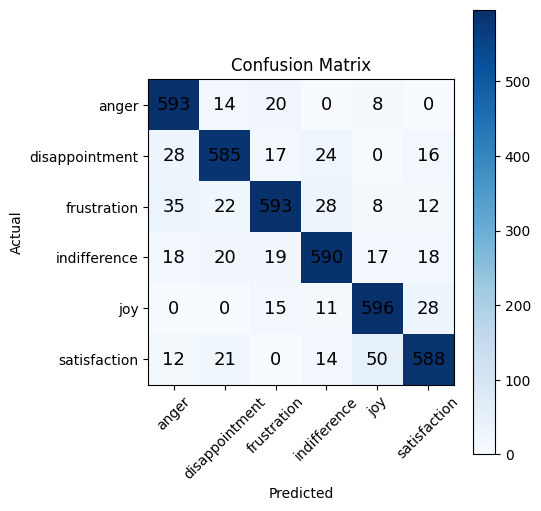

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
names = [id2label[i] for i in sorted(id2label)]

plt.figure(figsize=(5.5, 5.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(names)), names, rotation=45)
plt.yticks(range(len(names)), names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="black", fontsize=13)
plt.tight_layout(); plt.show()

## 12. Save & download the model

In [ ]:
model.save_pretrained("Hotel_BERT_Model")
tokenizer.save_pretrained("Hotel_BERT_Model")
print("Saved to ./Hotel_BERT_Model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to ./Hotel_BERT_Model


In [ ]:
!zip -r -q Hotel_BERT_Model.zip Hotel_BERT_Model
print("Zipped.")

Zipped.


## 13. Predict on new reviews
Because `id2label` is baked into the model config, the pipeline returns real class names directly.

In [ ]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model="Hotel_BERT_Model",
    tokenizer="Hotel_BERT_Model",
    device=0 if torch.cuda.is_available() else -1,
)

def predict(review):
    out = classifier(review)[0]
    print("Review     :", review)
    print("Sentiment  :", out["label"])
    print("Confidence :", round(out["score"] * 100, 2), "%")
    print("-" * 60)

predict("এনে সুন্দৰ অভিজ্ঞতাৰ বাবে মন প্ৰফুল্লিত হৈ পৰিল, নিশ্চয় পুনৰ আহিম।")   # joy
predict("মুঠতে মই সন্তুষ্ট, যি আশা কৰিছিলোঁ সেয়া পালোঁ।")                        # satisfaction
predict("এনে ভাল ৰেটিং দেখি আহিছিলোঁ, কিন্তু মন ভাঙি গ'ল।")                       # disappointment
predict("ইমান টকা লৈ এনে ব্যৱহাৰ, মোৰ খং উঠিল, অভিযোগ জনাম।")                     # anger
predict("বাৰে বাৰে একে সমস্যা হৈ থকাত মই অতিষ্ঠ হৈ পৰিলোঁ।")                       # frustration
predict("সাধাৰণ অভিজ্ঞতা, বিশেষ ভাল বা বেয়া একো নাই।")                            # indifference

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Review     : এনে সুন্দৰ অভিজ্ঞতাৰ বাবে মন প্ৰফুল্লিত হৈ পৰিল, নিশ্চয় পুনৰ আহিম।
Sentiment  : joy
Confidence : 92.27 %
------------------------------------------------------------
Review     : মুঠতে মই সন্তুষ্ট, যি আশা কৰিছিলোঁ সেয়া পালোঁ।
Sentiment  : satisfaction
Confidence : 92.86 %
------------------------------------------------------------
Review     : এনে ভাল ৰেটিং দেখি আহিছিলোঁ, কিন্তু মন ভাঙি গ'ল।
Sentiment  : disappointment
Confidence : 91.69 %
------------------------------------------------------------
Review     : ইমান টকা লৈ এনে ব্যৱহাৰ, মোৰ খং উঠিল, অভিযোগ জনাম।
Sentiment  : anger
Confidence : 92.25 %
------------------------------------------------------------
Review     : বাৰে বাৰে একে সমস্যা হৈ থকাত মই অতিষ্ঠ হৈ পৰিলোঁ।
Sentiment  : joy
Confidence : 91.54 %
------------------------------------------------------------
Review     : সাধাৰণ অভিজ্ঞতা, বিশেষ ভাল বা বেয়া একো নাই।
Sentiment  : indifference
Confidence : 91.01 %
-----------------------------------------------

In [ ]:
from google.colab import files
files.download("Hotel_BERT_Model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>